# An Intuitive Guide to Flow Matching

By [Tommy C](https://tommyc.xyz/)

[Solveit](https://share.solveit.pub/d/f3f1edbdaeca3085c535a76a112c4f37) · [Colab](https://colab.research.google.com/github/comhar/flow_matching_neurips/blob/main/flow_matching.ipynb) · [Blog](https://tommyc.xyz/posts/flow-matching) · [IPython](https://github.com/comhar/flow_matching_neurips/raw/refs/heads/main/flow_matching.ipynb) · [Markdown](https://github.com/comhar/flow_matching_neurips/raw/refs/heads/main/flow_matching.md)

## Introduction

The purpose of this guide is to develop an intuitive understanding of <a href="https://arxiv.org/abs/2210.02747" target="_blank" rel="noopener noreferrer">*Flow Matching*</a>, a technique used to generate a wide range of data from images to protein structures to robot trajectories. It is closely related to diffusion, the technique used in Stable Diffusion, DALL-E 2/3, and AlphaFold 3. In fact, diffusion can be viewed as a specific form of *Flow Matching*. 

While many *Flow Matching* guides can be very math heavy, this guide builds intuition step-by-step with concrete examples and uses high-school level math to derive *Flow Matching* from scratch. To build our intuition, we'll take inspiration from the human drawing process. We'll start by looking at how humans draw simple objects like a square. Next, we'll train a model to generate images with simple geometric patterns. During this process we'll formally define *Flow Matching* and implement it in code. The guide assumes you already have some experience training neural networks, so we won't explain every line of code.

*This guide's notation differs from the *Flow Matching* literature (e.g. [Lipman et al. 2024](https://arxiv.org/abs/2412.06264)). A terminology mapping and a list of related papers are included at the end of the guide.* 

## Drawing a Square

Let's start with the simple task of drawing a single black square on a white background. To accomplish this task we might use the following algorithm. First we decide on the size and location of the square, then we execute the following drawing steps:

1. draw the top side of the square
1. draw the right side of the square
1. draw the bottom side of the square
1. draw the left side of the square
1. fill in the square 

<div align="center">
  <img src="https://raw.githubusercontent.com/comhar/flow_matching_neurips/main/images/square.gif" alt="algorithm to draw a square" style="border-radius: 8px;" width="256" height="256">
  <p><em>Drawing a black square on a white background</em></p>
</div>

When drawing, we typically look at the current state of the drawing, decide what change is needed and then add that change. We repeat this process until the drawing is complete. 


We'll be using `pytorch` and the `diffusers` library. If these packages are not available in your current environment please uncomment the message below, run it and then restart your kernel.

In [1]:
# !pip install diffusers torch torchvision

In [2]:
import random
import torch
from PIL import Image
from torchvision import transforms

Let's write our drawing algorithm in code. To do this we'll create a function called `model` that takes the current drawing `img` and returns the change we need to add to `img`. We'll also pass in the current drawing step so `model` knows which action to perform (e.g. step 2: add the right side of the square).

In [3]:
def model(img, step, square_length, square_top_left_corner):
    "Return the change we need to add to `img` for `step` in the drawing algorithm."
    h, w = img.size()
    top, left = square_top_left_corner
    bottom, right = top+square_length-1, left+square_length-1
    change = torch.zeros(h, w)
    if step == 1: change[top, left:right] = -1.            # draw top side
    if step == 2: change[top:bottom, right] = -1.          # draw right side
    if step == 3: change[bottom, left+1:right+1] = -1.     # draw bottom side
    if step == 4: change[top+1:bottom+1, left] = -1.       # draw left side
    if step == 5: change[top+1:bottom, left+1:right] = -1. # fill in the square
    return change

*Note: As black pixels = 0, white pixels = 1, we need to subtract 1 to add a black pixel to the white background.*


To draw our square we need a blank sheet of paper (i.e. a tensor of ones).

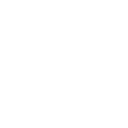

In [4]:
img = torch.ones(32, 32)
transforms.ToPILImage()(img).resize((128, 128), Image.NEAREST)

We'll need to display our drawing a bunch of times so let's create a function to do that.

In [5]:
def disp(img): return transforms.ToPILImage()(img).resize((128, 128), Image.NEAREST)

Let's select the size and location of the square we want to draw.

In [6]:
square_side_length = 8
top_left_corner = (4, 20)

Now, we can execute the first step of the drawing algorithm (add the top side).

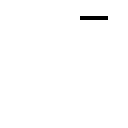

In [7]:
change = model(img, 1, square_side_length, top_left_corner)
img += change
disp(img)

Next, we execute the second step (add the right side). 

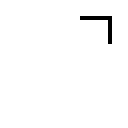

In [8]:
change = model(img, 2, square_side_length, top_left_corner)
img += change
disp(img)

We repeat this process until the drawing is complete.

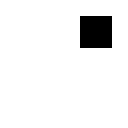

In [9]:
n_steps = 5
for step in range(3, n_steps+1):
    change = model(img, step, square_side_length, top_left_corner)
    img += change
disp(img)

## Drawing a Square Gradient

A simple square was pretty easy to break into discrete drawing steps that we could hardcode. What about drawing something a little more complex like this square gradient?

<div align="center">
  <img src="https://raw.githubusercontent.com/comhar/flow_matching_neurips/main/images/square_gradient.png" alt="black square gradient on a white background" style="border-radius: 8px;" width="256" height="256">
  <p><em>A black square gradient on a white background</em></p>
</div>

The steps for drawing the square gradient are less obvious. For a more complex image, like a landscape or a face, the steps would be even harder to work out. Instead of working out and hardcoding these steps ourselves, perhaps we could replace our `model` function with a neural network that can suggest what change to make at each step?


How would we train this network? We would need many examples of our square gradient at different steps in the drawing process. That brings us back to trying to figure out how to break the drawing down into discrete steps. Fortunately, neural networks don't need a drawing process built around familiar human actions like “draw this line” or “fill in this section.” Instead, they can learn a process that changes every pixel of the image a little bit at each step. It's much easier to generate examples for a drawing process like that.

For example, we could gradually blend a blank page into a square gradient over 100 drawing steps. At each step, we reduce the blank page's contribution by one percentage point and increase the square gradient's contribution by the same amount. At step 70, our image contains 30% blank page and 70% square gradient.

<div align="center">
  <img src="https://raw.githubusercontent.com/comhar/flow_matching_neurips/main/images/square_gradient.gif" alt="algorithm to draw a square gradient" style="border-radius: 8px;" width="256" height="256">
  <p><em>Drawing a black square gradient on a white background</em></p>
</div>

Here's the algorithm in mathematical form:

$$ x_n = (1-n)z + nx $$

- *$x_n$*: image at step *$n$*
- *$n$*: step in the process [0 to 1] (e.g. step 70 would be 0.7)
- *$z$*: starting image (blank page)
- *$x$*: the final image (square gradient)

Now that we've defined our drawing algorithm, we're ready to start training our neural network. This guide assumes you already have some experience with training neural networks. As a result, we won't discuss every piece of the training loop in detail. Instead, we'll focus on how to generate the input/target data used to train the model. All the other pieces of the training loop are pretty standard. 


*Note: This tutorial is intended to be run in an interactive notebook environment such as a Jupyter Notebook or Google Colab. If anything is unclear in the code below, please pause and experiment with it.*

Here's how we'll create a single input/target pair:

1. select a random drawing step [$n$]
1. generate a square gradient [$x$]
1. generate a white image [$z$]
1. compute $x_n$: $(1-n)z + nx$
1. compute $x_{n+\Delta n}$: $(1-(n+{\Delta n}))z + (n+{\Delta n})x$ [where $\Delta n = 0.01$]
1. use ($x_{n+\Delta n} - x_n$) as the target
 
In summary, we'll be passing ($x_n, n$) as input to the model and comparing the target ($x_{n+\Delta n} - x_n$) to the model's output/prediction.

Before we implement the steps above we need to modify step 3. To a human, a blank page allows us to create any image we want. It is an unconstrained source of creativity. The neural network equivalent of the blank page is random noise. Let's use that as our starting point $z$ instead.

Now we're ready to implement our training loop.

If `pytorch` and the `diffusers` packages are not available in your current environment please uncomment the message below, run it and then restart your kernel.

In [10]:
# !pip install diffusers torch

In [11]:
import random, time
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from diffusers import UNet2DModel

In [12]:
device = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'

We'll use 32x32 pixel images.

In [13]:
img_size = 32

In [14]:
def set_seed(seed=0): random.seed(seed); torch.manual_seed(seed)

Let's create a function to make our square gradients.

In [15]:
def make_square_gradient():
    half_width = random.uniform(4, 12) / 2
    center_x = random.uniform(half_width, img_size - half_width)
    center_y = random.uniform(half_width, img_size - half_width)
    rows, cols = torch.meshgrid(torch.arange(img_size), torch.arange(img_size), indexing='ij')
    dist_x = (cols - center_x).abs() - half_width      # horizontal dist from square edge
    dist_y = (rows - center_y).abs() - half_width      # vertical dist from square edge
    dist = torch.maximum(dist_x, dist_y).clamp(min=0)  # dist from square edge (0 inside square)
    return 1 - 2*torch.exp(-dist/3.0)                  # -1 inside square, fades to +1

In [16]:
def plot_squares():
    set_seed()
    fig, axes = plt.subplots(2, 2, figsize=(4, 4))
    for ax in axes.flat:
        ax.imshow(make_square_gradient(), cmap='gray', vmin=-1, vmax=1)
        ax.axis('off')


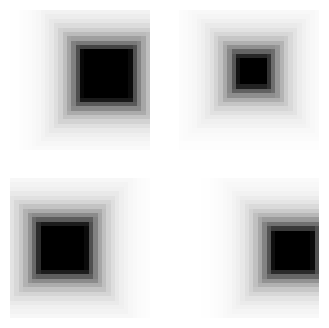

In [17]:
plot_squares()

In [18]:
def logger(train_loss, epoch, total_epochs, t0):
    if epoch % 100 != 0 and epoch != total_epochs-1: return
    if epoch == 0:
        print("| Epoch | Train Loss | Elapsed |")
        print("|-------|------------|---------|")
    print(f"| {epoch:5d} | {train_loss:10.4f} | {time.time()-t0:6.1f}s |")

*Note: We don't compute a validation loss as we'll be generating a random dataset at every training step.*

In [19]:
def train(model, loss_fn, logger_fn, mk_dataset_fn, epochs=500, bs=64, lr=0.01):
    set_seed()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs, pct_start=0.3)
    t0 = time.time()
    for epoch in range(epochs):
        (xn, n), (tgt,) = mk_dataset_fn(bs=bs)
        pred = model(xn, n.flatten()).sample
        loss = loss_fn(pred, tgt)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        logger_fn(loss.item(), epoch, epochs, t0)
    total = time.time() - t0
    print(f"Total: {total:.1f}s ({total/epochs:.2f}s/epoch)")
    return model

We'll use a tiny UNet which should be fast to train and hopefully good enough to learn the square gradient pattern.

In [20]:
def get_model(): 
    return UNet2DModel(
        sample_size=img_size, in_channels=1, out_channels=1,
        block_out_channels=(16, 32), norm_num_groups=8,
        down_block_types=("DownBlock2D", "DownBlock2D"),
        up_block_types=("UpBlock2D", "UpBlock2D"),
    ).to(device)


Now let's implement a function that creates our input/target pairs.

In [21]:
def mk_dataset(bs=64):
    x = torch.stack([make_square_gradient().unsqueeze(0) for _ in range(bs)]).to(device)
    n = torch.rand(bs,1,1,1, device=device)*0.99
    z = torch.randn(bs,1,img_size,img_size,device=device)
    xn = (1-n)*z + n*x
    xn_dn = (1-(n+0.01))*z + (n+0.01)*x
    return (xn, n), (xn_dn-xn,)

Finally let's train the model.

In [22]:
model = train(get_model(), F.mse_loss, logger, mk_dataset, epochs=250)

| Epoch | Train Loss | Elapsed |
|-------|------------|---------|
|     0 |     0.0799 |    0.3s |
|   100 |     0.0001 |   10.3s |
|   200 |     0.0000 |   20.3s |
|   249 |     0.0000 |   25.2s |
Total: 25.2s (0.10s/epoch)


Our loss is encouraging. Now, let's see what the model can generate. To generate images from our model we use a similar process to our hardcoded square example from before. We loop through each drawing step, ask the model what change to add, and update the image. The only difference is that we now start from random noise and take 100 small steps instead of 5.


In [23]:
def sample(model):
    model.eval()
    with torch.no_grad():
        x = torch.randn(1, 1, img_size, img_size, device=device)
        n_steps = 100
        for step in range(n_steps):
            n = torch.tensor([step * 0.01], device=device)
            x = x + model(x, n).sample
    return x[0, 0].cpu()

In [24]:
def plot_samples():
    set_seed()
    fig, axes = plt.subplots(2, 2, figsize=(4, 4))
    for ax in axes.flat:
        ax.imshow(sample(model), cmap='gray', vmin=-1, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
    plt.show()

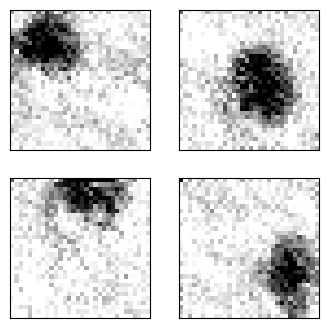

In [25]:
plot_samples()


The model has learned to generate a dark blob. This is a reasonable start, but we're a long way from generating the square gradient pattern. It's interesting to note that our loss is tiny, yet the model clearly hasn't learned our desired pattern. Let's take a closer look at our target and figure out why we're seeing this contradiction.

## Why the Model Fails: Deriving Flow Matching

Recall the definition of $x_n$ and $x_{n+\Delta n}$:

$$x_n = (1-n)z + nx$$

$$x_{n+\Delta n} = (1-(n+\Delta n))z + (n+\Delta n)x$$

Expanding $x_{n+\Delta n}$:

$$
\begin{aligned}
x_{n+\Delta n} &= (1-n)z + nx - \Delta n \, z + \Delta n \, x \\
&= (1-n)z + nx + \Delta n \,(x-z)
\end{aligned}
$$

Subtracting $x_n$ from both sides gives us our target:

$$x_{n+\Delta n} - x_n = \Delta n\,(x - z)$$

With $\Delta n = 0.01$, we're effectively training our model to predict a target whose individual pixels are 100 times smaller than those of $x$ or $z$. To see why this is a problem, let's roughly compute the loss for a lazy model outputting all zeros. 

MSE (mean squared error) loss compares each predicted pixel $p_i$ to its target pixel $t_i$, squares the differences, and averages:

$$\text{MSE} = \frac{1}{N}\sum_i (p_i - t_i)^2$$

If the model outputs all zeros ($p_i = 0$), the loss is just the average squared target pixel:

$$\text{MSE} = \frac{1}{N}\sum_i t_i^2$$

Our target pixels are $t_i = \Delta n\,(x_i - z_i)$. Since $x$ is in the range $[-1, 1]$ and $z$ is standard noise, the pixels of $x - z$ are roughly of size 1, so each squared term is $\approx (0.01 \times 1)^2 = 0.0001$. This means a lazy model gets a near perfect loss without learning the fine details of the square gradient.

How can we force the model to learn these finer details? One approach is to remove $\Delta n$ from the target during training, so the model is trained to predict $x - z$ instead of the rather tiny $\Delta n\,(x - z)$. Then at sampling time, we scale the model's output by $\Delta n$ before adding it to the image. 

Let's make these tweaks now to our `mk_dataset` and `sample` functions and see how it does.

First let's update `mk_dataset`.

In [26]:
def mk_dataset(bs=64):
    x = torch.stack([make_square_gradient().unsqueeze(0) for _ in range(bs)]).to(device)
    n = torch.rand(bs, 1, 1, 1, device=device)
    z = torch.randn(bs, 1, img_size, img_size, device=device)
    xn = (1-n)*z + n*x
    return (xn, n), (x-z,)

Re-run our training loop.

In [27]:
model = train(get_model(), F.mse_loss, logger, mk_dataset, epochs=500)

| Epoch | Train Loss | Elapsed |
|-------|------------|---------|
|     0 |     1.6248 |    0.1s |
|   100 |     0.1617 |   10.1s |
|   200 |     0.0855 |   20.1s |
|   300 |     0.0821 |   30.2s |
|   400 |     0.0824 |   40.2s |
|   499 |     0.0719 |   50.1s |
Total: 50.1s (0.10s/epoch)


Now, let's update our sampler to scale the model's output by $\Delta n$.

In [28]:
def sample(model):
    model.eval()
    with torch.no_grad():
        x = torch.randn(1, 1, img_size, img_size, device=device)
        n_steps = 100
        for step in range(n_steps):
            n = torch.tensor([step * 0.01], device=device)
            x = x + 0.01 * model(x, n).sample
    return x[0, 0].cpu()

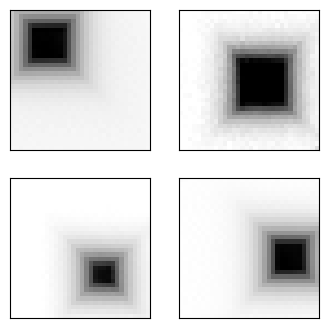

In [29]:
plot_samples()


These results are much better! The model can now generate our square gradient pattern. The samples are a little noisy but the model has clearly learned the general pattern.

Believe it or not, you've just trained a model with *Flow Matching*. Specifically, you've used its linear-path variant, which is one of the most popular variants.

Let's take a step back for a minute. We started with a 12-line Python function that helped us draw simple squares. It did this by telling us what change to add to the current image at each step. Then we replaced this function with a neural network that did the same thing. With some high-school algebra and basic debugging, we've derived *Flow Matching* from scratch 😍.


In the introduction we briefly mentioned the connection between *Diffusion* and *Flow Matching*. In our example, we created training images using a simple linear blend of random noise and square gradients. Diffusion also creates training images by blending noise and images, but typically blends them in a different way.

## Conclusion

That's it! I hope this guide has helped you build an intuitive understanding of *Flow Matching* and that you're ready to apply it to a problem in your own field. The next section includes some advice on how to do that. If you decide to try this out, let me know how it goes.

## Exercise: Flow Matching in Your Field

To apply *Flow Matching* to a problem in your field, start by answering these three questions:

1. What is my target data $x$, and how do I collect it?
1. What is my starting point $z$? Random noise or something I need to generate from $x$?
1. How can I blend $z$ into $x$ in a smooth, continuous way?

Once you've answered these questions, start off with a smaller, simpler version of your problem. When you get good results on that problem, slowly increase the complexity. This is usually the quickest way to make progress.

Here are a few examples to spark your imagination.

**Image Colourisation**

Train a model to take a black and white image as input and colourise it. This is an interesting example because the starting point $z$ is a black and white image not random noise. Generating a dataset is easy: take colour images $x$, convert them to black and white, and you have your $(z, x)$ pairs. A toy version of this problem could be as simple as creating images containing a single shape (triangle, square, circle). Make all the triangles various shades of green, the squares shades of red, and the circles different shades of blue.

**Birdsong Generation**

Train a model to generate a short audio clip of a bird call. As the starting point $z$ is random noise, generating the dataset is a matter of downloading an existing birdsong dataset and cropping it into short clips to create the targets $x$. A toy version of this problem could be generating pure sine waves, which can sound similar to some birds. Create clips of half a second, each containing a sine wave with 1 of 5 frequencies, 1 of 5 amplitudes and some random phase.

**Protein Folding**

Train a model to take a list of amino acids with random 3D coordinates ($z$) and output their folded coordinates ($x$). This is a very challenging problem. A toy version could be creating a dataset of imaginary amino acid sequences with imaginary amino acids. Start with sequences of 10 amino acids all of the same type and assume they always fold into a specific shape (e.g. pyramid, cube, sphere). You can control the complexity even further by choosing starting positions where some or all of the amino acids are close to their folded positions.

## Terminology Mapping

Here's a mapping from the terminology used in this guide to the terminology used in the *Flow Matching* literature (e.g. [Lipman et al. 2024](https://arxiv.org/abs/2412.06264)):

| This guide | Literature (symbol) | Literature (name) |
|---|---|---|
| $n$ (drawing step, 0 to 1) | $t$ | time |
| $z$ (starting image / noise) | $x_0$ | source |
| $x$ (final image) | $x_1$ | target |
| $x_n = (1-n)z + nx$ | $x_t = (1-t)x_0 + t x_1$ | linear path |
| $x - z$ (the model's target) | $u_t = x_1 - x_0$ | conditional velocity field |
| `model` | $u_t^\theta$ or $v_\theta$ | learned velocity field |

In this guide `sampling from the model` translates as `solving the ODE (numerically)`.

## Related Papers

The original paper and a follow-up guide from the team that introduced *Flow Matching*:

- [Flow Matching for Generative Modeling](https://arxiv.org/abs/2210.02747) — Lipman et al. (2023)
- [Flow Matching Guide and Code](https://arxiv.org/abs/2412.06264) — Lipman et al. (2024)

Some applications of *Flow Matching* in different fields:

- **Image Generation**: [Scaling Rectified Flow Transformers for High-Resolution Image Synthesis](https://arxiv.org/abs/2403.03206) — Esser et al. (2024)
- **Speech Generation**: [Voicebox: Text-Guided Multilingual Universal Speech Generation at Scale](https://arxiv.org/abs/2306.15687) — Le et al. (2023)
- **Video-to-Audio**: [Frieren: Efficient Video-to-Audio Generation Network with Rectified Flow Matching](https://arxiv.org/abs/2406.00320) — Wang et al. (2024)
- **Protein Engineering**: [AlphaFold Meets Flow Matching for Generating Protein Ensembles](https://arxiv.org/abs/2402.04845) — Jing et al. (2024)